# AI and Machine Learning CA1 (classification)

Name: Kendrick Slamat

Class: DAAA/FT/1B/03

Admin No: p2510877

# Task Overview

We will be predicting the status of a factory machine based on information collected from different machines tabulated on a dataset collected from a manufacturing factory, using a machine learning model to predict if a given machine is working or faulty.

### Why this problem matters
Predicting machine status is crucial for manufacturing because it enables:
- Proactive maintenance and early detection of faults
- Reduced costly downtime and prevention of unexpected breakdowns
- Improved operational efficiency and optimized resource allocation
- Enhanced product quality and consistency
- Data-driven decision-making and cost savings through predictive maintenance
Machine learning transforms raw sensor data into actionable insights, supporting smarter factory operations

# Learning Objectives

Within this assignment, I will be creating a classification model with the proper supervised machine learning workflow.

- Data Loading and Cleaning: Loading datasets from files and handling missing values, duplicates, and inconsistencies to ensure data quality.

-   Data Visualization: Using numpy, pandas, matplotlib and seaborn to further analyse relationships between data and view distributions with different plots to gain a visual understanding of the data.

-   Data Preprocessing: Using numpy and pandas to read data, analyse features, prepare data by cleaning and formatting data for the model to understand.

-   Model Hyperparameter Tuning: Using scikit-learn to use different algorithms and experiment with different hyperparameters to see which works best for the model to do well and train data with the highest appropriate accuracy.

-   Evaluation Metrics: Using scikit-learn, matplotlib and seaborn to evaluate data using metrics such as recall, precision and F1 score to gain a better understanding of how well different algorithms perform using the same dataset.

-   Feature Analysis: Find out which features are the most important and significantly impact the outcome of the model.

Firstly, we will import all used methods from the libraries used: scikit-learn, numpy, pandas, matplotlib and seaborn.


In [1]:
# Import necessary libraries to be used.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import copy
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_score, recall_score, f1_score
import warnings
from catppuccin import PALETTE

warnings.filterwarnings("ignore")
# Create a color palette for matplotlib and seaborn
flavour = PALETTE.mocha
sns.set_palette([c.hex for c in flavour.colors])
plt.style.use(flavour.identifier)
sns.set_theme(
        context="notebook",
        style="darkgrid",
        rc={
            "figure.facecolor": flavour.colors.mantle.hex,
            "axes.facecolor": flavour.colors.base.hex,
            "axes.edgecolor": flavour.colors.surface0.hex,
            "grid.color":     flavour.colors.surface1.hex,
            "text.color":        flavour.colors.text.hex,
            "axes.labelcolor":   flavour.colors.text.hex,
            "xtick.color":       flavour.colors.subtext0.hex,
            "ytick.color":       flavour.colors.subtext0.hex,
        },
    )


# Step 1: Data Loading

#### Extracting Data from the CSV file

We will be extracting data from the dataset given from the CSV file. We will then do a little preview and primer of the key features of this dataset. This will allow us to identify the data types and type of variables that are within this dataset. It also tells us useful information on the number of rows of our dataset, and shows us how a few rows of our dataset would look like.


In [2]:
# Read dataset, replace file path with dataset file path.
df = pd.read_csv("datasets/factory_data.csv")

In [3]:
# Show info on dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unique ID             20000 non-null  int64  
 1   Product ID            20000 non-null  object 
 2   Quality               19009 non-null  object 
 3   Ambient T (C)         20000 non-null  float64
 4   Process T (C)         19600 non-null  float64
 5   Rotation Speed (rpm)  18812 non-null  float64
 6   Torque (Nm)           20000 non-null  float64
 7   Tool Wear (min)       20000 non-null  int64  
 8   Machine Status        20000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.4+ MB


In [4]:
# Show first few rows of dataset
df.head()

,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,1,K12965,M,24.95,35.45,1551.0,42.8,0,0
1,2,Z62710,L,25.05,35.55,1408.0,46.3,3,0
2,3,T20224,L,24.95,35.35,1498.0,49.4,5,0
3,4,Z33024,L,25.05,35.45,1433.0,39.5,7,0
4,5,Z52839,L,25.05,35.55,1408.0,40.0,9,0


In [5]:
# Show a description of numerical features
df.describe()

,Unique ID,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
count,20000.000000,20000.000000,19600.000000,18812.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,26.904930,36.904291,1538.795397,39.986910,107.951000,0.033900
std,5773.647028,2.000834,1.483647,178.674963,9.968684,63.652555,0.180976
min,1.000000,22.150000,32.550000,1168.000000,3.800000,0.000000,0.000000
25%,5000.750000,25.250000,35.750000,1423.000000,33.200000,53.000000,0.000000
50%,10000.500000,26.950000,36.950000,1503.000000,40.100000,108.000000,0.000000
75%,15000.250000,28.450000,37.950000,1613.000000,46.800000,162.000000,0.000000
max,20000.000000,31.450000,40.750000,2886.000000,76.600000,253.000000,1.000000


In [6]:
print("Summary of dataset: ")
print(f"Total Samples: {df.shape[0]}")
print(f"Total Features: {df.shape[1]}")
print(f"\nFeature Types:")
print(df.dtypes.value_counts())

Summary of dataset: 
Total Samples: 20000
Total Features: 9

Feature Types:
float64    4
int64      3
object     2
Name: count, dtype: int64


## Reflection

We took a quick look at the dataset through various pandas methods such as head, describe and info. This tells us a lot of useful information about the dataset. From this alone, we can conclude that the dataset itself has 20000 rows of data. We are also exposed to a preview of the data, and we can see a mix of numerical and categorical features. In the future, we will be dealing with data on a more deeper level, by analyzing data trends and identifying potential pitfalls that could cause our model to perform worse than expected.


# Step 2: Data Cleaning / Explanatory Data Analysis

We can see that our dataset gives us 8 features to work with, with the target feature to be "Machine Status".
We can see that the dataset also yields different features with different data types.
Based on the data, we can categorize and determine if the features are necessary to help the model in its predictions.
We can also see that the count of some of the features is not 20000. This means that we have missing data within our dataset.

Dataset Overview:

    Unique ID: A unique identifier for each machine. (number, discrete)

    Product ID: Identifies the specific product being manufactured. (string, nominal)

    Quality: Categorises operational quality as L (Low), M (Medium), and H (High). (string, ordinal)

    Ambient Temperature (°C): The temperature surrounding the machine. (number, continuous)

    Process Temperature (°C): The operating temperature during the manufacturing process. (number, continuous)

    Rotation Speed (rpm): The machine's rotational speed. (number, continuous)

    Torque (Nm): The torque exerted by the machine. (number, continuous)

    Tool Wear (min): The duration the tool has been in use. (number, continuous)

    Machine Status: The target variable where 0 indicates normal operation, and 1 indicates a fault. (number, discrete)

Let's proceed by checking if our dataset contains any missing values.


In [7]:
# Check for null values
df.isnull().sum()

Unique ID                  0
Product ID                 0
Quality                  991
Ambient T (C)              0
Process T (C)            400
Rotation Speed (rpm)    1188
Torque (Nm)                0
Tool Wear (min)            0
Machine Status             0
dtype: int64

There is missing data within our dataset. Let's try to check for duplicates in our entire dataset.


In [8]:
# Check for duplicates
duplicates = df[df.duplicated()]

if not duplicates.empty: 
    print(duplicates.head(5))
else:
    print("No duplicates found in the Dataset.")

No duplicates found in the Dataset.


Great! No duplicates were found in our dataset.

To tackle the problem of missing values, we will impute (replace) these missing values with appropriate aggregated values. This approach preserves data integrity while addressing missing data.

There are 991 missing values in Quality, 400 missing values in Process T(C), and 1188 missing values in Rotation Speed(rpm).

Quality is an ordinal categorical variable while Process Temperature and Rotation Speed are numerical variables. For Quality, we will impute values using the most frequent value (mode), and for the numerical features we will impute values using the mean.

**Avoiding data leakage:** the mode and the means must be computed from the *training* split only. If we imputed now, on all 20,000 rows, statistics from the test set would leak into the training data and our test score would be optimistic. So in this step we only encode Quality as an ordinal number (L = 0, M = 1, H = 2) and leave the missing values as `NaN`. The imputers are fitted later, inside the modelling pipeline, after the train/test split.


In [9]:
# Convert Quality from a categorical feature into an ordinal numerical feature (L < M < H).
# Missing values stay as NaN here: imputation is fitted inside the modelling pipeline on the
# training split only, so no statistics from the test set leak into training.
df["Quality"] = df["Quality"].map({"L": 0, "M": 1, "H": 2})

# Do a deep copy of our dataset for future use.
ori_df = copy.deepcopy(df)

df.isnull().sum()


Unique ID                  0
Product ID                 0
Quality                  991
Ambient T (C)              0
Process T (C)            400
Rotation Speed (rpm)    1188
Torque (Nm)                0
Tool Wear (min)            0
Machine Status             0
dtype: int64

Quality is now numeric, and the missing values will be handled by the pipeline after the split. Now let's check to see if our data has any outliers.
To do this, we will use the interquartile range method to determine outliers within each of our features.


In [10]:
# Check for outliers using boxplots for numerical features
numerical_cols = ["Ambient T (C)", "Process T (C)", "Rotation Speed (rpm)", "Torque (Nm)", "Tool Wear (min)"]
for column in numerical_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1   
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    print(f"{column}: {len(outliers)} outliers detected.")

Ambient T (C): 0 outliers detected.
Process T (C): 0 outliers detected.
Rotation Speed (rpm): 771 outliers detected.
Torque (Nm): 138 outliers detected.
Tool Wear (min): 0 outliers detected.


Here are the outliers that are visualised by the outlier points shown as dots on the boxplots.


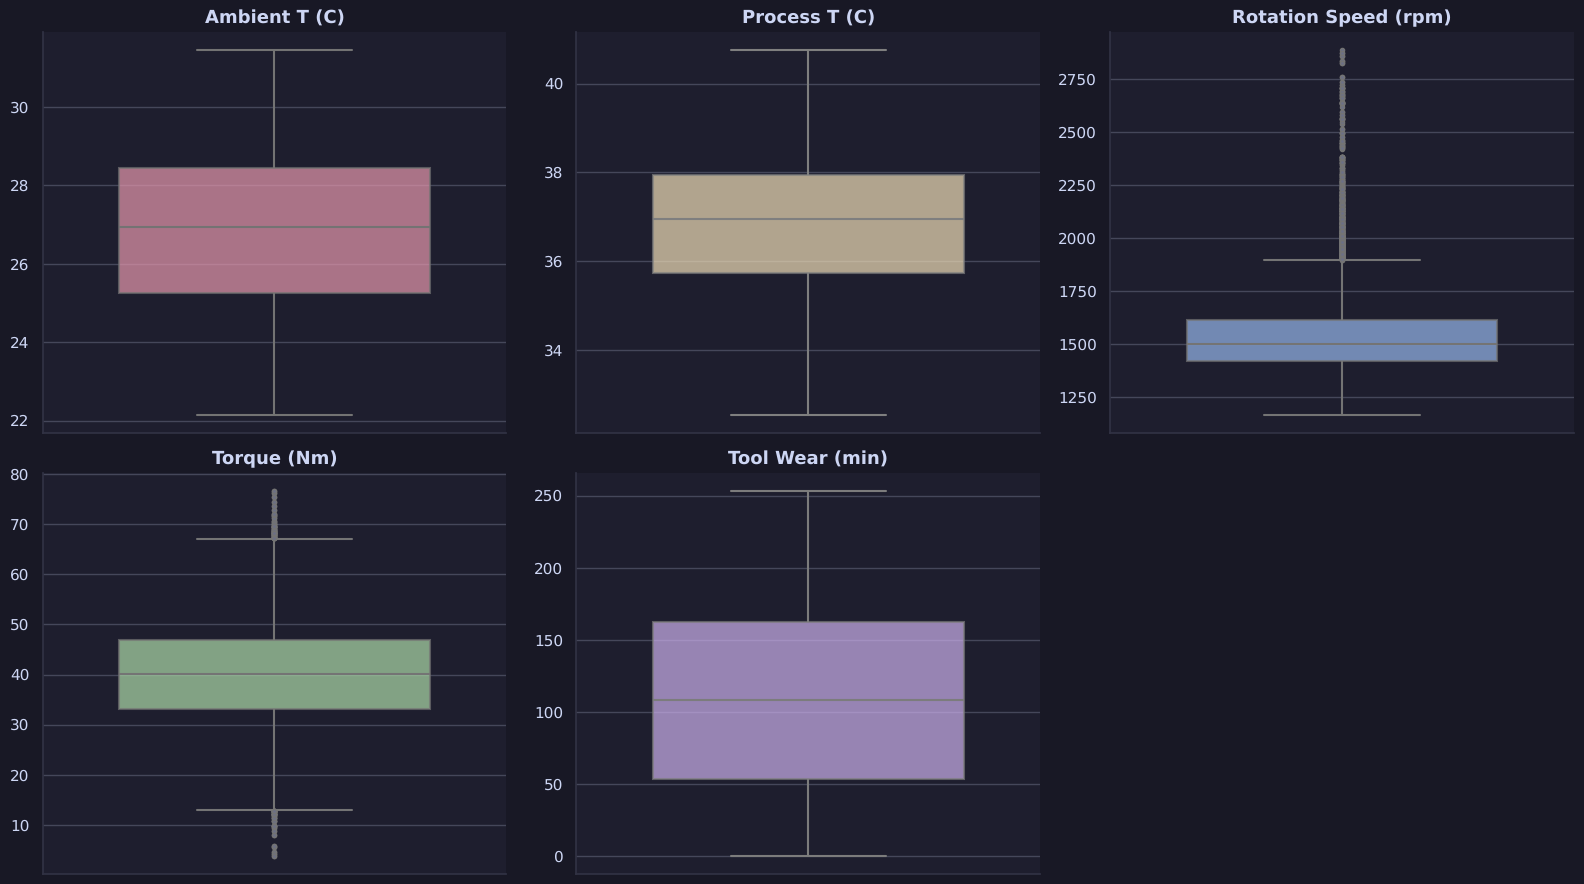

In [11]:
plt.figure(figsize=(16, 9))
box_colors = [flavour.colors.red.hex, flavour.colors.yellow.hex, flavour.colors.blue.hex, flavour.colors.green.hex, flavour.colors.mauve.hex]
# Create boxplots for different features to show outliers visualized.
num = 1
for idx, col in enumerate(numerical_cols):
    plt.subplot(2, 3, num)
    ax = sns.boxplot(
        data=df,
        y=col,
        width=0.67,
        color=box_colors[idx % len(box_colors)],
        linewidth=1.5,
        fliersize=3,
        boxprops=dict(alpha=0.7)
    )
    ax.set_ylabel("")
    ax.set_title(col, fontsize=13, fontweight='bold')
    sns.despine()
    num += 1

plt.tight_layout()
plt.show()
num = 1

There are outliers as shown above for features (Torque with roughly 138 outliers, and Rotation Speed with roughly 955 outliers.)

I have considered not to exclude these outliers from the dataset because they are **real measurements** that were taken, and removing them could potentially make us lose important information for training our model. Natural measurements often produce a wide range of measurements hence the Interquartile rule can sometimes potentially mark it down as a flawed outlier when it is not.

Lastly, let's see if our dataset is balanced.


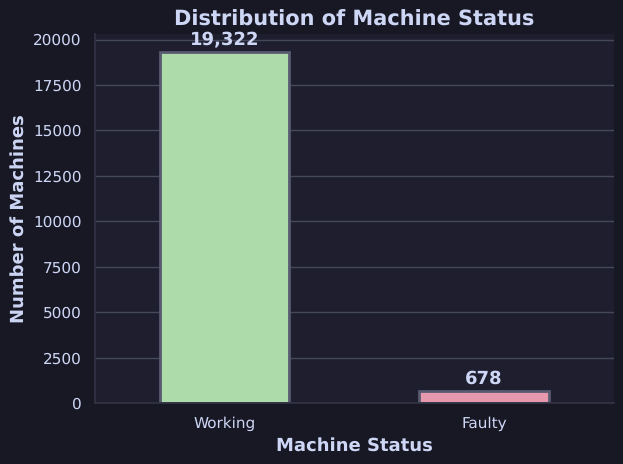

In [12]:
# Count the number of each machine status
status_count = df["Machine Status"].value_counts().to_frame(name="count")

# Prepare status_count for plotting
status_count_plot = status_count.reset_index()
status_count_plot["Machine Status"] = status_count_plot["Machine Status"].map({0: "Working", 1: "Faulty"})

# Create barplot to see distribution of feature
ax = sns.barplot(
    data=status_count_plot,
    x="Machine Status",
    y="count",
    width=0.5,
    palette=[flavour.colors.green.hex, flavour.colors.red.hex],
    edgecolor=flavour.colors.surface2.hex,
    linewidth=2
)
sns.despine()
for i, v in enumerate(status_count_plot["count"]):
    ax.text(i, v + 200, f"{v:,}", ha='center', va='bottom', fontsize=13, fontweight='bold', color=flavour.colors.text.hex)
ax.set_ylabel("Number of Machines", fontsize=13, fontweight='bold')
ax.set_xlabel("Machine Status", fontsize=13, fontweight='bold')
ax.set_title("Distribution of Machine Status", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

We will carry out SMOTE (Synthetic Minority Oversampling Technique) to generate more samples for the minority class during training.

## Reflection

In summary, we performed exploratory data analysis (EDA) on our dataset. We found missing values in three features and decided to impute them inside the modelling pipeline (after the train/test split) to avoid data leakage. We found no duplicates. We scanned for outliers with the interquartile range method and kept them, as they are real measurements. Lastly, we found that our dataset is severely imbalanced (3.4% faulty machines), which we will handle with oversampling on the training data only.


# Step 3 : Data Visualization

In this section, We will be visualizing all our features using matplotlib and seaborn to get a better view of both categorical and numerical features, within a cleaned dataset that has been preprocessed. This will help us better visualise trends, and perform feature engineering to see which variables can be dropped or if any variables have similar relationships, they can be merged.

We will be using a pairplot to visualize relationships between features as well as a correlation matrix to numerically identify the strength and direction of feature relationships.


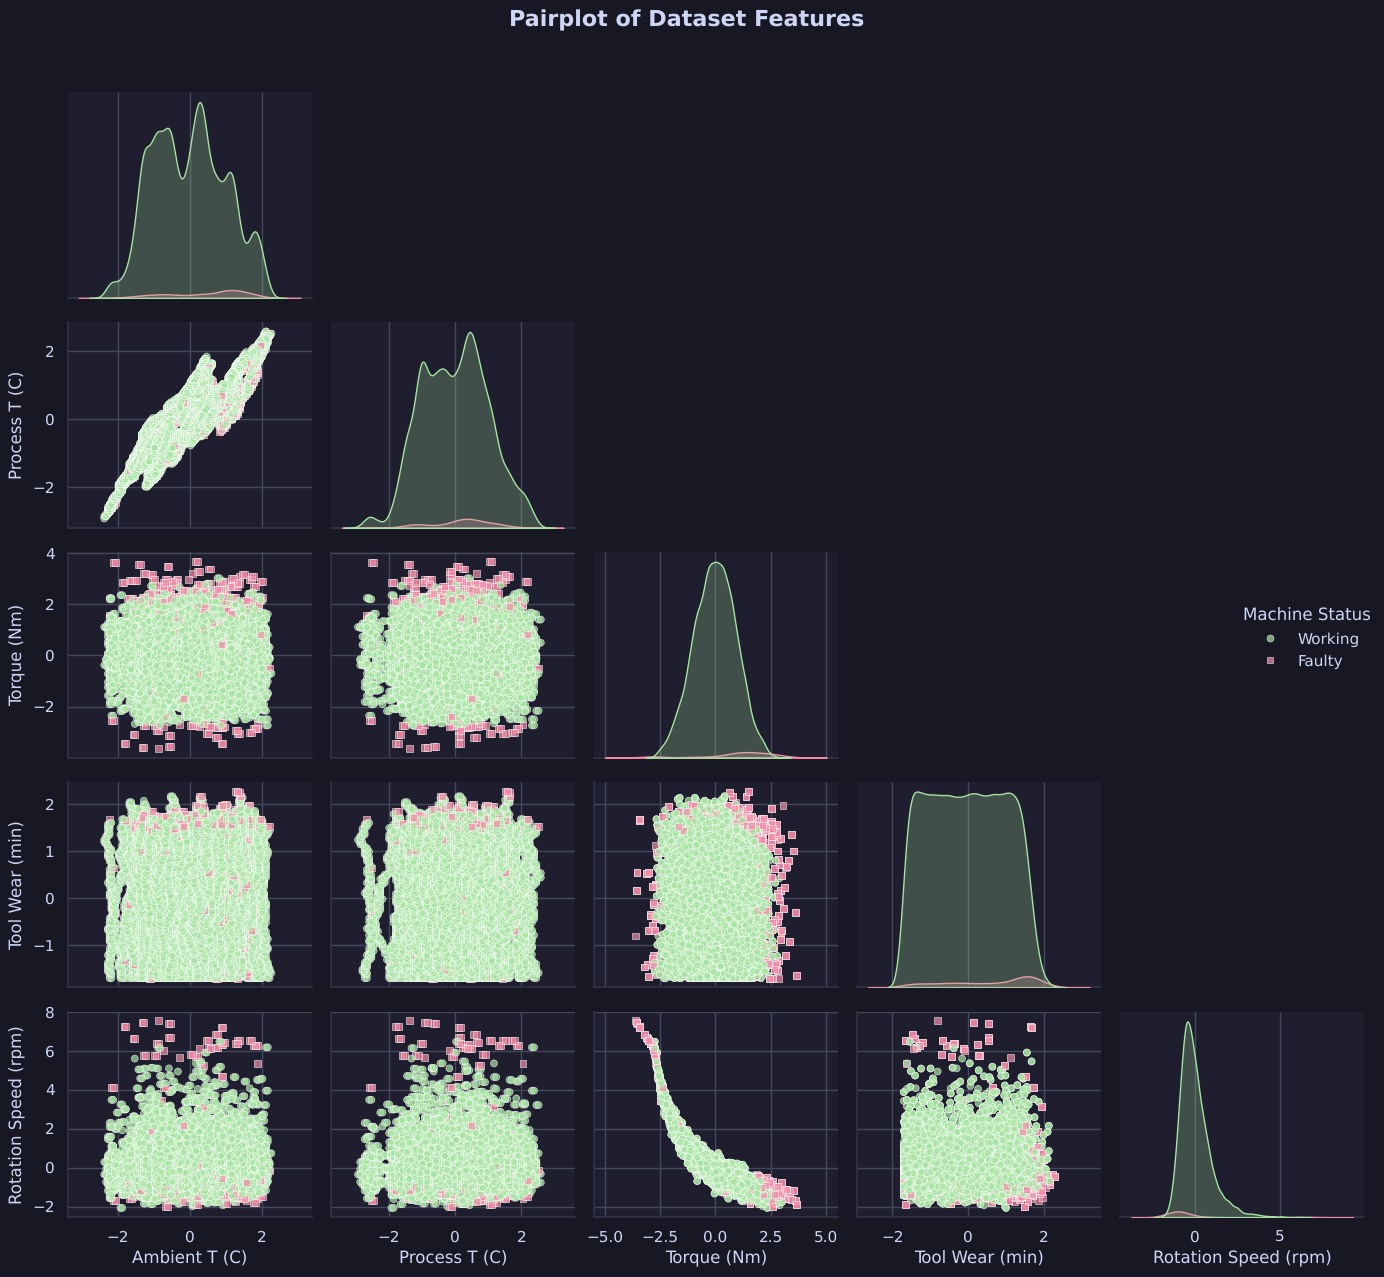

In [13]:
# Use StandardScaler to put features on a common scale for this plot only (EDA, not model training).
# Rows with missing values are dropped for plotting.
plot_cols = ["Ambient T (C)", "Process T (C)", "Torque (Nm)", "Tool Wear (min)", "Rotation Speed (rpm)"]
plot_df = df[plot_cols + ["Machine Status"]].dropna()
scaled = pd.DataFrame(StandardScaler().fit_transform(plot_df[plot_cols]), columns=plot_cols, index=plot_df.index)

# color palette for pairplot: working (0) = green, faulty (1) = red
pairplot_palette = [flavour.colors.green.hex, flavour.colors.red.hex]
pairplot_kwargs = dict(
    diag_kind="kde",
    corner=True,
    plot_kws=dict(alpha=0.7, s=25, edgecolor="w", linewidth=0.5),
    markers=["o", "s"],
    palette=pairplot_palette,
    hue="Machine Status"
)
# plot a pairplot
scaled = pd.concat([scaled, plot_df["Machine Status"]], axis=1)
ax = sns.pairplot(data=scaled, **pairplot_kwargs)
plt.suptitle('Pairplot of Dataset Features', y=1.02, fontsize=16, fontweight='bold')
ax._legend.texts[0].set_text("Working")
ax._legend.texts[1].set_text("Faulty")
plt.tight_layout()
plt.show()


This pairplot shows the relations between different features, and the spread of data to see if we can visualize any trends.

Some trends we can see from this plot:

1. **Torque** and **Rotation Speed** have a strong non-linear (inverse) relationship, and faulty machines sit mostly at the extremes of this curve (very high torque at low speed, or very low torque at high speed).
2. The plot is dominated by working machines, because only 3.4% of the machines in the dataset are faulty.
3. **Ambient Temperature** and **Process Temperature** move together: they are strongly positively related.
4. Both temperature features have similar distribution shapes.


#### Correlation Matrix

We will construct a correlation matrix to visualize the strength and direction of relationships between our numerical features. This heatmap will help us identify:

- **Highly correlated features** that may be redundant (correlation close to +1 or -1)
- **Independent features** with weak correlations (close to 0)
- **Potential multicollinearity issues** that could affect model performance

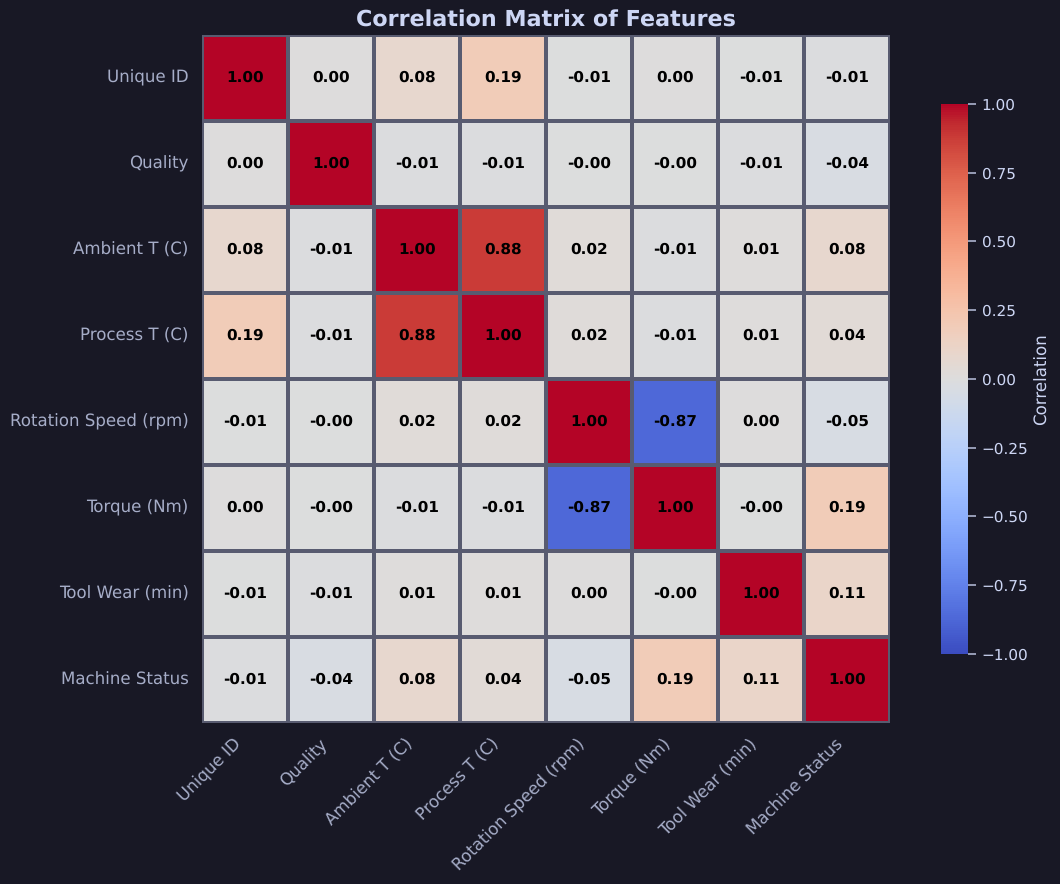

In [14]:
# Plot a correlation heatmap to visualize relationships between features.
plt.figure(figsize=(12, 9))
sns.heatmap(
    df.drop("Product ID", axis=1).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=1.5,
    linecolor=flavour.colors.surface2.hex,
    cbar_kws={"shrink": 0.8, "label": "Correlation"},
    square=True,
    vmin=-1,
    vmax=1,
    annot_kws={"fontsize": 11, "fontweight": "bold", "color": "#000000"}
)
plt.title("Correlation Matrix of Features", fontsize=16, fontweight="bold", color=flavour.colors.text.hex)
plt.xticks(rotation=45, ha="right", fontsize=12, color=flavour.colors.subtext0.hex)
plt.yticks(rotation=0, fontsize=12, color=flavour.colors.subtext0.hex)
plt.tight_layout()
plt.show()

We can see that Ambient Temperature and Process Temperature are strongly related, with a positive correlation of 0.87.
Rotation Speed and Torque have a strong negative correlation of -0.85, showing that they are almost inversely proportional.


#### Individual Feature Analysis

We will now display both our numerical and categorical features by visualizing them using boxplots to see the distribution of data and values, as well as a bar chart for categorical features to show the count of each categorical feature in the datset itself.

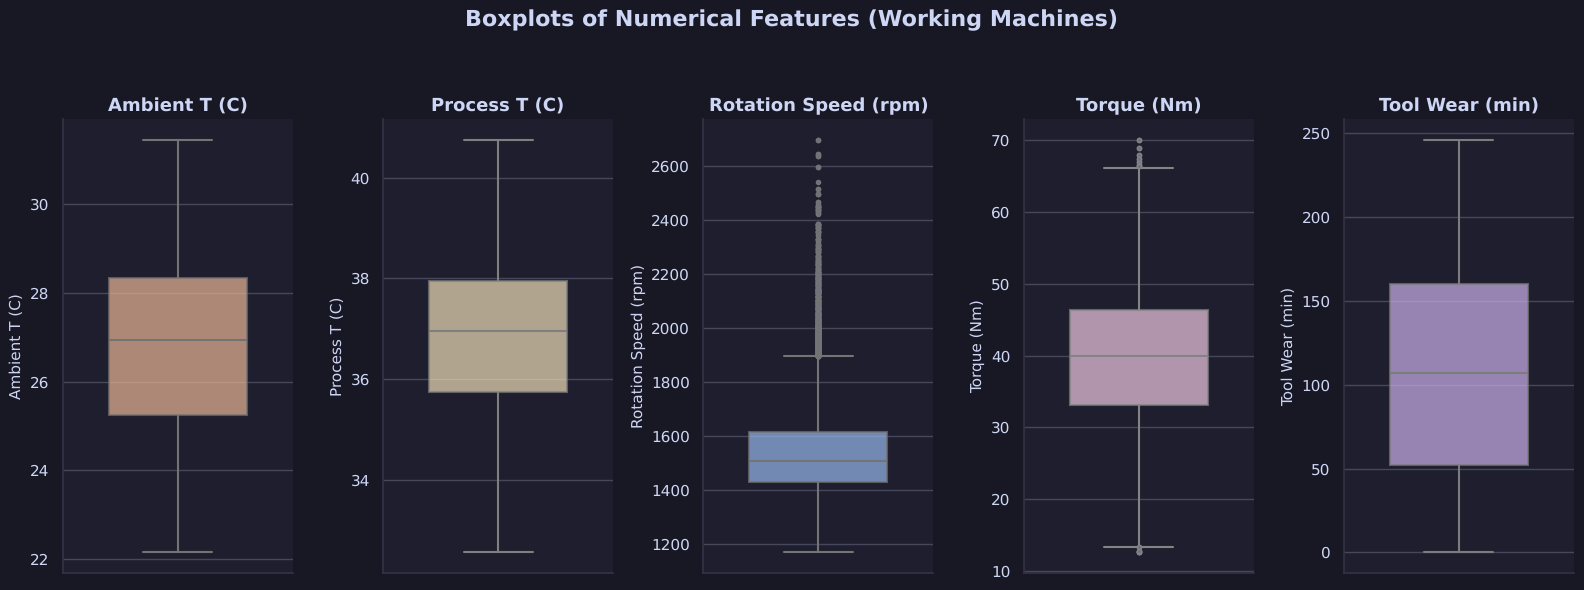

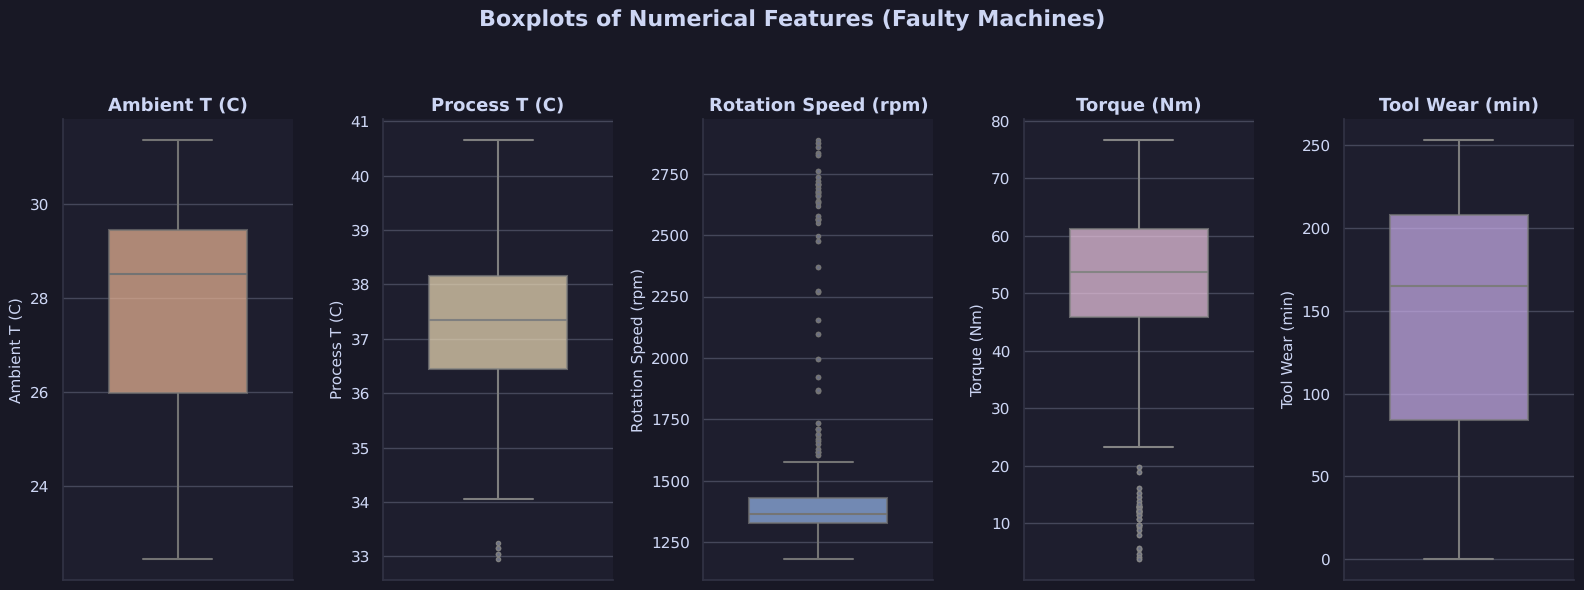

In [15]:
box_colors = [flavour.colors.peach.hex, flavour.colors.yellow.hex, flavour.colors.blue.hex, flavour.colors.pink.hex, flavour.colors.mauve.hex]

# Plot a boxplot for Working machines
plt.figure(figsize=(16, 6))
plt.suptitle("Boxplots of Numerical Features (Working Machines)", fontsize=16, fontweight='bold')
working_df = df[df["Machine Status"] == 0]
for idx, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), idx + 1)
    sns.boxplot(
        data=working_df,
        y=col,
        color=box_colors[idx % len(box_colors)],
        width=0.6,
        fliersize=3,
        linewidth=1.5,
        boxprops=dict(alpha=0.7)
    )
    plt.title(col, fontsize=13, fontweight='bold')
    plt.ylabel(col, fontsize=11)
    plt.xlabel("")
    sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Plot a boxplot for Faulty machines
plt.figure(figsize=(16, 6))
plt.suptitle("Boxplots of Numerical Features (Faulty Machines)", fontsize=16, fontweight='bold')
faulty_df = df[df["Machine Status"] == 1]
for idx, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), idx + 1)
    sns.boxplot(
        data=faulty_df,
        y=col,
        color=box_colors[idx % len(box_colors)],
        width=0.6,
        fliersize=3,
        linewidth=1.5,
        boxprops=dict(alpha=0.7)
    )
    plt.title(col, fontsize=13, fontweight='bold')
    plt.ylabel(col, fontsize=11)
    plt.xlabel("")
    sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

We have hidden the outliers and adjusted our plot to show the entire dataset to visualize the distribution across multiple features. Outliers are kept within the plot they represent actual measurements that can show us machine behavior and potential failure patterns.


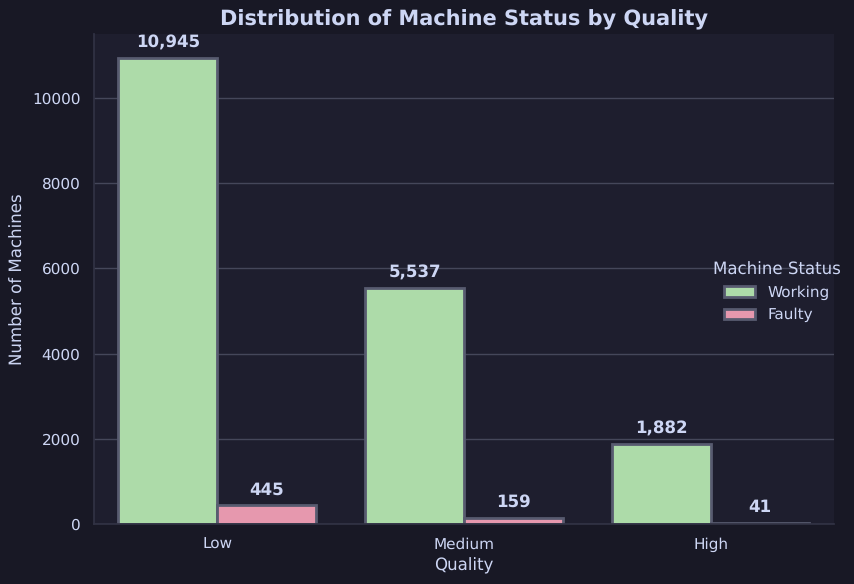

In [16]:
quality_labels = ["Low", "Medium", "High"]
status_palette = {"Working": flavour.colors.green.hex, "Faulty": flavour.colors.red.hex}

df_plot = df.copy()
df_plot["Quality"] = df_plot["Quality"].map({0: "Low", 1: "Medium", 2: "High"})
df_plot["Machine Status"] = df_plot["Machine Status"].map({0: "Working", 1: "Faulty"})
# Plot a countplot of Quality, showing both faulty and working machines.
ax = sns.catplot(
    kind="count",
    data=df_plot,
    x="Quality",
    order=quality_labels,
    hue="Machine Status",
    hue_order=["Working", "Faulty"],
    palette=status_palette,
    height=6,
    aspect=1.2,
    edgecolor=flavour.colors.surface2.hex,
    linewidth=2
)

for p in ax.ax.patches:
    if p.get_height() > 0:
        ax.ax.annotate(
            f"{int(p.get_height()):,}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='bottom', fontsize=12, fontweight='bold', color=flavour.colors.text.hex, xytext=(0, 5), textcoords='offset points'
        )
ax._legend.set_title("Machine Status")
ax.set_axis_labels("Quality", "Number of Machines")
plt.title("Distribution of Machine Status by Quality", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


### Data Visualization Insights

- **Torque and Rotation Speed** show clear separation between faulty and working machines in the boxplots and pairplot. This suggests they are strong predictors, so we will definitely keep them in the final feature set.
- **Ambient Temperature and Process Temperature** are strongly correlated (correlation = 0.87). This motivates our later decision to combine them into a single "Temperature Difference" feature, reducing redundancy.
- **Tool Wear** also shows a distinct distribution between classes, indicating it is likely an important predictor.
- **Quality** appears less clearly separated, but as an ordinal feature (L < M < H), it may still provide useful information.

**Summary of Findings:**
- The dataset is highly imbalanced (working >> faulty).
- Torque, Rotation Speed, and Tool Wear are likely key drivers of faults.
- Ambient and Process Temperatures are redundant; will be combined.
- Quality is ordinal and will be encoded as such.
- These findings directly inform our feature engineering and selection in the next step.

# Step 4: Data Preprocessing

We will now prepare the data for the models. The order of operations matters here, because any step that *learns* something from the data (a mean, a mode, a scaling factor, synthetic samples) must only learn it from the training data.

#### 1. Feature Engineering and Selection

Based on our EDA:

1. **Unique ID** - This is just an identifier and has no predictive value for machine status, so we drop it.
2. **Product ID** - An identifier for the product, so we drop it.
3. **Ambient T (C) and Process T (C)** - Strongly correlated (0.87). We combine them into a single **Temperature Difference** feature.

These are row-wise operations that do not learn anything from the data, so they are safe to do before the split.

#### 2. Split the dataset into training and test sets

We split the data 80% / 20% with `train_test_split`, using `stratify=y` so that both splits keep the same 3.4% fault rate, and a fixed random state for reproducibility. The test set is then put aside and only used **once**, to evaluate the final model.

#### 3. A leakage-free modelling pipeline

Everything that is fitted goes into an `imblearn` `Pipeline`, so that during cross-validation it is re-fitted on each training fold and never sees the validation fold or the test set:

1. **Imputation** - mean for numerical features, mode for Quality.
2. **Oversampling** - our dataset is severely imbalanced (96.6% working vs 3.4% faulty). **SMOTE** generates synthetic faulty machines so the model does not simply learn to predict "working". Because Quality is an ordinal category, we use **SMOTE-NC**, which keeps Quality on its real L/M/H levels instead of creating values like 1.37. Oversampling happens only on the data used for fitting, never on the data used for scoring.
3. **Scaling** - `StandardScaler` to give every feature mean 0 and standard deviation 1. Algorithms like SVM, KNN and Logistic Regression are sensitive to feature magnitudes (e.g. Temperature: 20-40 °C vs Rotation Speed: 1200-2800 rpm).
4. **Model**.


#### Creating a Temperature Difference feature

The temperature difference feature was made by subtracting the difference between Process Temperature and Ambient Temperature. This difference shows the thermal delta that the machine operates under, which could be a better indicator of a machine's temperature tolerance than the individual temperature readings. By combining these correlated features into a single meaningful metric, we reduce dimensionality while potentially capturing more relevant information about the machine's operating conditions that could make the machines fail.

In [17]:
# We could transform Ambient Temperature and Process Temperature into a new feature.
df["Temperature Difference (C)"] = df["Process T (C)"] - df["Ambient T (C)"]
df.head()

,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status,Temperature Difference (C)
0,1,K12965,1.0,24.95,35.45,1551.0,42.8,0,0,10.5
1,2,Z62710,0.0,25.05,35.55,1408.0,46.3,3,0,10.5
2,3,T20224,0.0,24.95,35.35,1498.0,49.4,5,0,10.4
3,4,Z33024,0.0,25.05,35.45,1433.0,39.5,7,0,10.4
4,5,Z52839,0.0,25.05,35.55,1408.0,40.0,9,0,10.5


Let's Visualize the temperature difference feature to see its distribution.

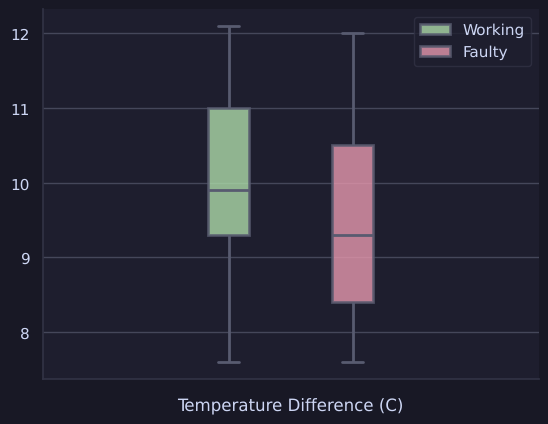

In [18]:
# Plot a boxplot of the temperature difference feature
ax = sns.boxplot(
    data=df,
    y="Temperature Difference (C)",
    hue="Machine Status",
    width=0.5,
    gap=0.67,
    linecolor=flavour.colors.surface2.hex,
    linewidth=2,
    whis=(0, 100),
    palette=[flavour.colors.green.hex, flavour.colors.red.hex],
    fliersize=3,
    boxprops=dict(alpha=0.8)
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Working", "Faulty"])
plt.ylabel("")
plt.xlabel("Temperature Difference (C)")
sns.move_legend(ax,"upper right")
sns.despine()


In [19]:
# Select the modelling features. Unique ID and Product ID are identifiers, and the two raw
# temperatures are replaced by the engineered Temperature Difference.
features = ["Quality", "Temperature Difference (C)", "Torque (Nm)", "Tool Wear (min)", "Rotation Speed (rpm)"]
X = df[features]
y = df["Machine Status"]
X.head()


,Quality,Temperature Difference (C),Torque (Nm),Tool Wear (min),Rotation Speed (rpm)
0,1.0,10.5,42.8,0,1551.0
1,0.0,10.5,46.3,3,1408.0
2,0.0,10.4,49.4,5,1498.0
3,0.0,10.4,39.5,7,1433.0
4,0.0,10.5,40.0,9,1408.0


Note that the features are **not** scaled or imputed yet. Those steps are fitted inside the pipeline, after the split.

In [20]:
# Split data into train and test sets *before* any fitted preprocessing (imputation, SMOTE, scaling).
# stratify=y keeps the fault rate identical in both splits.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2, stratify=y)
print(f"Train: {X_train.shape[0]} rows, {y_train.sum()} faulty ({y_train.mean():.2%})")
print(f"Test:  {X_test.shape[0]} rows, {y_test.sum()} faulty ({y_test.mean():.2%})")


Train: 16000 rows, 542 faulty (3.39%)
Test:  4000 rows, 136 faulty (3.40%)


In [21]:
def build_pipeline(model, features):
    """Impute -> oversample -> scale -> model. Every step is fitted on training data only."""
    num_features = [f for f in features if f != "Quality"]
    transformers = [("num", SimpleImputer(strategy="mean"), num_features)]
    if "Quality" in features:
        transformers.append(("quality", SimpleImputer(strategy="most_frequent"), ["Quality"]))
        # SMOTE-NC keeps Quality on its discrete L/M/H levels instead of interpolating between them.
        sampler = SMOTENC(categorical_features=[len(num_features)], random_state=42)
    else:
        sampler = SMOTE(random_state=42)
    return ImbPipeline([
        ("impute", ColumnTransformer(transformers)),
        ("smote", sampler),
        ("scale", StandardScaler()),
        ("model", model),
    ])


def feature_names(features):
    """Column order produced by the pipeline's imputation step."""
    return [f for f in features if f != "Quality"] + (["Quality"] if "Quality" in features else [])


In [22]:
# Look at what the imputation and oversampling steps do to the training split.
# (Inside the pipeline this happens automatically; the test split is never resampled.)
demo = build_pipeline(DummyClassifier(), features)
X_train_imp = demo.named_steps["impute"].fit_transform(X_train)
X_train_smt, y_train_smt = demo.named_steps["smote"].fit_resample(X_train_imp, y_train)
X_train_smt = pd.DataFrame(X_train_smt, columns=feature_names(features))
print(f"Missing values after imputation + SMOTE-NC: {int(X_train_smt.isnull().sum().sum())}")
print(f"Quality levels after SMOTE-NC: {sorted(X_train_smt['Quality'].unique())}")


Missing values after imputation + SMOTE-NC: 0
Quality levels after SMOTE-NC: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]


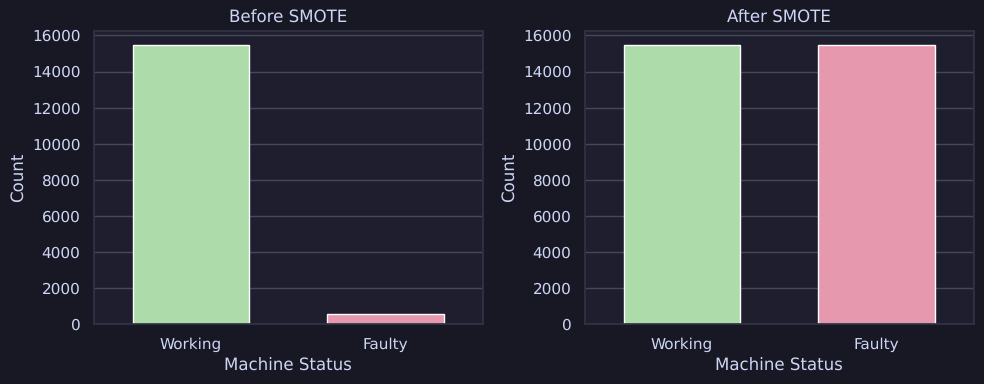

Before SMOTE: 
Machine Status
0    15458
1      542
Name: count, dtype: int64
After SMOTE: 
Machine Status
0    15458
1    15458
Name: count, dtype: int64


In [23]:
# Visualize class distribution before and after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, ax=axes[0], palette=[flavour.colors.green.hex, flavour.colors.red.hex], width=0.6)
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Machine Status")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["Working", "Faulty"])

sns.countplot(x=y_train_smt, ax=axes[1], palette=[flavour.colors.green.hex, flavour.colors.red.hex], width=0.6)
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Machine Status")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels(["Working", "Faulty"])

plt.tight_layout()
plt.show()
print("Before SMOTE: ")
print(y_train.value_counts())
print("After SMOTE: ")
print(pd.Series(y_train_smt).value_counts())


SMOTE balances the two classes in the training data, and SMOTE-NC kept Quality on its real levels, so no re-imputation is needed afterwards.

Before we go ahead with actual model training, we will use a dummy baseline model and see how it performs.

DummyClassifier Baseline Performance
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3864
           1       0.00      0.00      0.00       136

    accuracy                           0.97      4000
   macro avg       0.48      0.50      0.49      4000
weighted avg       0.93      0.97      0.95      4000



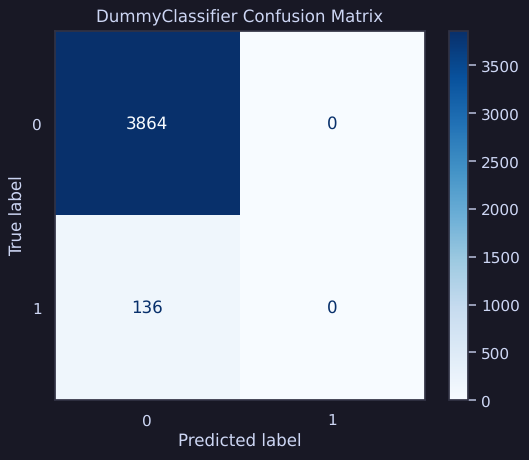

In [24]:
# Create a dummy classifier to evaluate baseline performance.
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Print out some evaluation metrics. we will discuss in detail how the metrics work later.
print("DummyClassifier Baseline Performance")
print(classification_report(y_test, y_pred_dummy, zero_division=False))
cm_dummy = confusion_matrix(y_test, y_pred_dummy)
disp_dummy = ConfusionMatrixDisplay(confusion_matrix=cm_dummy, display_labels=dummy.classes_)
fig, ax = plt.subplots()
disp_dummy.plot(ax=ax, cmap="Blues")
ax.grid(False)
plt.title("DummyClassifier Confusion Matrix")
plt.show()


### Baseline Reflection

Before training advanced models, I established a baseline using `DummyClassifier` with the "most frequent" strategy. This classifier always predicts the majority class (working machines), completely ignoring the input features.

The results show very high accuracy (due to class imbalance) but **zero recall and precision for the minority class (faulty machines)**. This highlights the importance of using more sophisticated models and proper evaluation metrics (like recall and F1-score) for imbalanced datasets. Comparing all subsequent models to this baseline ensures that any improvement is meaningful and not just due to the dataset's skewed distribution.

## Reflection

After completing data preprocessing and feature engineering, our data is ready for model training, without any leakage from the test set.

1. **Feature Engineering**: Created the Temperature Difference feature by subtracting Ambient Temperature from Process Temperature, replacing two strongly correlated features with one.

2. **Feature Selection**: Removed Unique ID and Product ID, which are identifiers. The candidate features are Quality, Temperature Difference (C), Torque (Nm), Tool Wear (min) and Rotation Speed (rpm).

3. **Train-Test Split**: Divided the dataset into 80% training (16,000 machines, 542 faulty) and 20% testing (4,000 machines, 136 faulty). Stratification keeps the fault rate at 3.4% in both splits.

4. **Leakage-free pipeline**: Imputation, SMOTE-NC oversampling and scaling are all inside one pipeline, so they are only ever fitted on training data. On the full training set, SMOTE-NC balances the classes from 15,458 : 542 to 15,458 : 15,458 while keeping Quality on its real L/M/H levels.

5. **Baseline**: The majority-class dummy model reaches 97% accuracy but finds none of the faulty machines, which confirms that accuracy is the wrong metric for this problem.


# Step 5: Model Training

In this step, we will train and evaluate multiple classification algorithms to determine which model best predicts machine status. We'll test five different algorithms, each with unique strengths for handling our classification problem:

## Classification Algorithms Overview

### 1. **Logistic Regression**
A linear model that predicts the probability of binary outcomes using a logistic function. Logistic Regression works by finding the best-fitting linear decision boundary between classes.

**Strengths:**
- Fast training and prediction
- Interpretable coefficients showing feature importance
- Works well with linearly separable data
- Low computational requirements

**Weaknesses:**
- Assumes linear relationship between features and log-odds
- May underperform with complex, non-linear patterns
- Sensitive to outliers

### 2. **Support Vector Machine (SVM)**
SVM finds the optimal hyperplane that maximizes the margin between classes. It uses kernel functions to transform data into higher dimensions, enabling it to handle non-linear decision boundaries.

**Strengths:**
- Effective in high-dimensional spaces
- Robust to outliers through margin maximization
- Versatile through different kernel functions (linear, RBF, polynomial)
- Works well with clear margin of separation

**Weaknesses:**
- Computationally expensive with large datasets
- Requires careful hyperparameter tuning
- Difficult to interpret compared to simpler models
- Sensitive to feature scaling

### 3. **Random Forest**
An ensemble learning method that constructs multiple decision trees during training and outputs the mode of their predictions. Each tree is trained on a random subset of data and features, reducing overfitting.

**Strengths:**
- Handles non-linear relationships effectively
- Robust to outliers and noise
- Provides feature importance rankings
- Reduces overfitting through ensemble averaging
- Requires minimal feature scaling

**Weaknesses:**
- Can be computationally intensive with many trees
- Less interpretable than single decision trees
- May overfit on noisy datasets
- Slower prediction time compared to linear models

### 4. **K-Nearest Neighbors (KNN)**
A non-parametric, instance-based learning algorithm that classifies data points based on the majority class of their k nearest neighbors in the feature space.

**Strengths:**
- Simple and intuitive algorithm
- No training phase (lazy learning)
- Naturally handles multi-class problems
- Adapts well to new training data

**Weaknesses:**
- Computationally expensive during prediction
- Sensitive to feature scaling
- Performance degrades with high-dimensional data (curse of dimensionality)
- Requires careful selection of k parameter
- Sensitive to imbalanced datasets

### 5. **Gradient Boosting**
An ensemble technique that builds models sequentially, where each new model corrects errors made by previous models. It combines weak learners (typically shallow decision trees) to create a strong predictive model.

**Strengths:**
- Often achieves highest accuracy among standard algorithms
- Handles mixed data types well
- Captures complex non-linear relationships
- Provides feature importance
- Robust to outliers

**Weaknesses:**
- Prone to overfitting if not properly tuned
- Longer training time due to sequential nature
- Requires careful hyperparameter tuning
- Less interpretable than simpler models
- Sensitive to noisy data


We'll train all five algorithms on our preprocessed dataset and evaluate them using multiple metrics (precision, recall, F1-score, and accuracy). This comprehensive comparison will reveal which algorithm best handles our imbalanced dataset and captures the patterns distinguishing faulty from working machines.


To pick a model **without touching the test set**, we compare all five algorithms with 5-fold stratified cross-validation on the training data. Each fold re-fits the whole pipeline (imputation, SMOTE-NC, scaling and model) on the other four folds, then predicts the held-out fold. We pool these out-of-fold predictions to compute precision, recall and F1 for the faulty class, and display a confusion matrix for each algorithm.

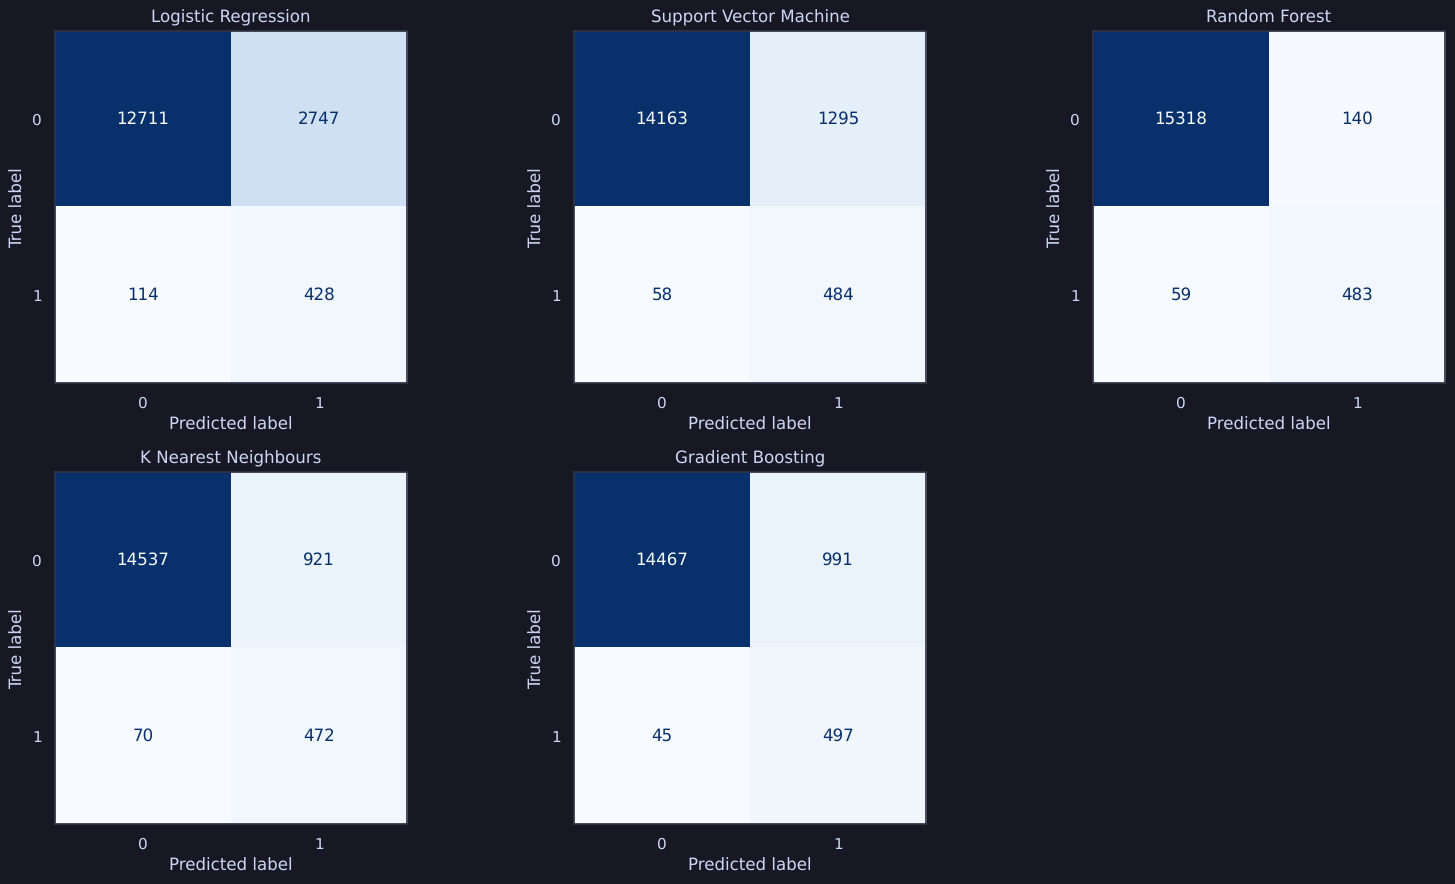

,Precision,Recall,F1
Model,,,
Random Forest,0.775,0.891,0.829
Gradient Boosting,0.334,0.917,0.490
K Nearest Neighbours,0.339,0.871,0.488
Support Vector Machine,0.272,0.893,0.417
Logistic Regression,0.135,0.790,0.230


In [25]:
# Compare classification models with 5-fold stratified cross-validation on the training set.
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "K Nearest Neighbours": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
plt.figure(figsize=(16,9))
for num, (k, model) in enumerate(models.items(), start=1):
    y_oof = cross_val_predict(build_pipeline(model, features), X_train, y_train, cv=kf, n_jobs=-1)
    cv_rows.append({
        "Model": k,
        "Precision": precision_score(y_train, y_oof),
        "Recall": recall_score(y_train, y_oof),
        "F1": f1_score(y_train, y_oof),
    })
    ax = plt.subplot(2,3,num)
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_train, y_oof), display_labels=[0, 1])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(k)
    ax.grid(False)
plt.tight_layout()
plt.show()

cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("F1", ascending=False)
cv_df.round(3)


#### Model Evaluation

The table and confusion matrices above come from 5-fold stratified cross-validation on the training set, so the test set has not been used yet.

Metrics and what they mean:

**Precision**: Measures the accuracy of positive predictions. It answers "Of all the machines we predicted as faulty, how many were actually faulty?" Formula: True Positives / (True Positives + False Positives). High precision means fewer false alarms. (important!)

**Recall**: Measures how well we identify all actual positive cases. It answers "Of all the machines that were actually faulty, how many did we correctly identify?" Formula: True Positives / (True Positives + False Negatives). High recall means we catch most faults. (important!)

**Accuracy**: Overall correctness of the model. It answers "Of all predictions, how many were correct?" Formula: (True Positives + True Negatives) / Total Predictions. However, accuracy can be misleading with imbalanced datasets. (not important due to the imbalanced dataset)

**F1-Score**: Harmonic mean of precision and recall, providing a balanced measure when you need to consider both false positives and false negatives equally. (important! This is our main metric.)

**Performance Analysis (faulty class, cross-validated):**

| Model | Precision | Recall | F1 |
|---|---:|---:|---:|
| **Random Forest** | **0.775** | 0.891 | **0.829** |
| Gradient Boosting | 0.334 | **0.917** | 0.490 |
| K Nearest Neighbours | 0.339 | 0.871 | 0.488 |
| Support Vector Machine | 0.272 | 0.893 | 0.417 |
| Logistic Regression | 0.135 | 0.790 | 0.230 |

1. **All models reach high recall (79–92%)** thanks to SMOTE: they all learn to flag most faulty machines.
2. **They differ mainly in precision.** Logistic Regression, SVM, KNN and Gradient Boosting raise between two and six false alarms for every real fault, while Random Forest raises fewer than one false alarm for every three real faults.
3. **Random Forest has by far the best F1 (0.83)**, well ahead of the next best model (Gradient Boosting, 0.49).

We will now visualize each model's learning curve to learn more about our machine learning models' effectiveness.


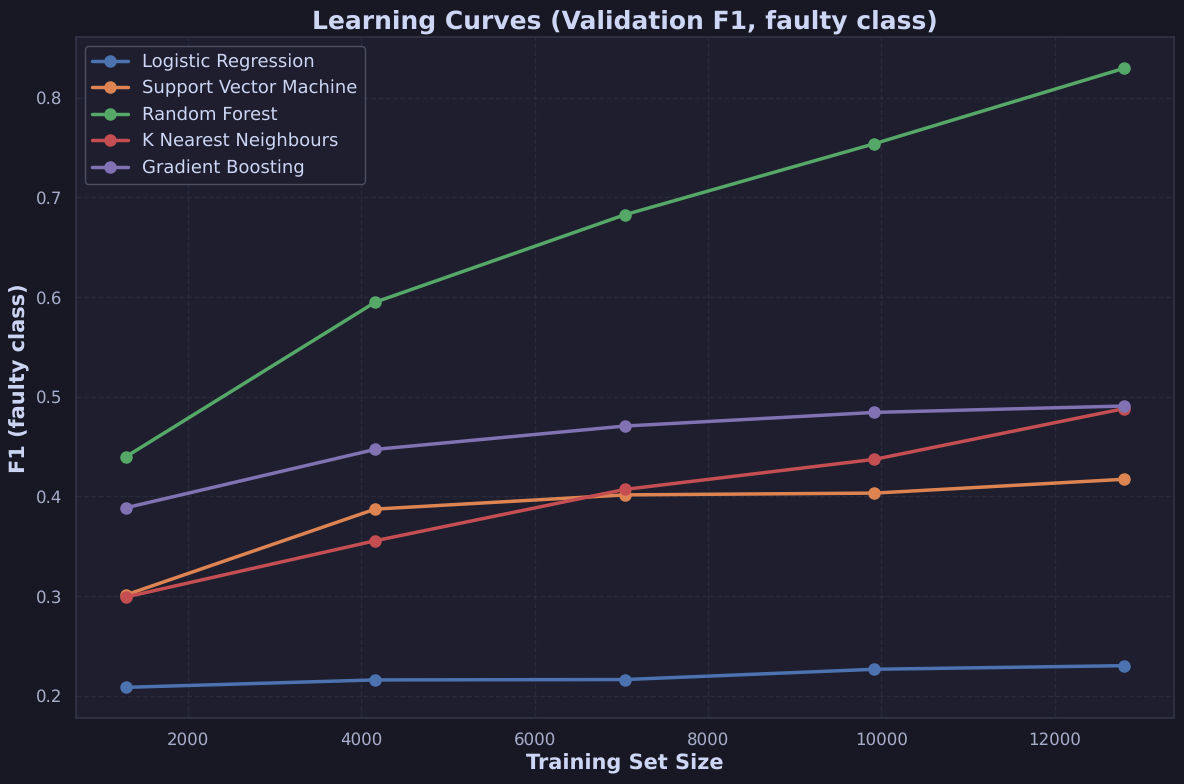

In [26]:
# Plot learning curves of the faulty-class F1 score on the validation folds.
# The whole pipeline (including SMOTE) is re-fitted on every training subset, so synthetic
# samples never end up in a validation fold.
plt.figure(figsize=(12, 8))
for n, m in models.items():
    train_sizes, train_scores, val_scores = learning_curve(
        build_pipeline(m, features), X_train, y_train,
        scoring="f1",
        train_sizes=np.linspace(0.1, 1.0, 5),
        n_jobs=-1, cv=kf
    )
    val_mean = val_scores.mean(axis=1)
    plt.plot(
        train_sizes, val_mean, marker='o', linewidth=2.5, markersize=8,
        label=f"{n}"
    )

plt.title("Learning Curves (Validation F1, faulty class)", fontsize=18, fontweight='bold', color=flavour.colors.text.hex)
plt.xlabel("Training Set Size", fontsize=15, fontweight='bold', color=flavour.colors.text.hex)
plt.ylabel("F1 (faulty class)", fontsize=15, fontweight='bold', color=flavour.colors.text.hex)
plt.legend(fontsize=13, frameon=True, facecolor=flavour.colors.base.hex, edgecolor=flavour.colors.surface2.hex)
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(fontsize=12, color=flavour.colors.subtext0.hex)
plt.yticks(fontsize=12, color=flavour.colors.subtext0.hex)
plt.tight_layout()
plt.show()


The learning curves show that **Random Forest benefits the most from more data**: its validation F1 rises steadily from 0.44 with about 1,300 training machines to 0.83 with the full training folds, and it is still rising. Gradient Boosting, SVM and KNN improve more slowly and stay below 0.5, and Logistic Regression stays flat around 0.23, because a linear decision boundary cannot separate the faulty machines. This confirms that the non-linear interactions between torque, rotation speed and tool wear are best captured by Random Forest.


**Best Model Selection:**

**Random Forest emerges as the best performing algorithm** for this factory machine classification task. It has the best balance between precision and recall for fault detection (cross-validated F1 0.83, precision 0.78, recall 0.89), and its learning curve is still improving.

**Key Insights:**

Random Forest outperforms the other algorithms even without hyperparameter tuning, so we will tune it next.


# Step 6: Hyperparameter Tuning and Optimization
#### Hyperparameter Tuning.

On the previous step, we have obtained random forest as the best model to complete our classification problem. We can continue improving and iterating the model by carrying out extensive feature engineering to improve its evaluation metrics, as well as understand its hyperparameters and fine tune the model into a better one. We will now continue the train -> eval -> test loop for hyperparameter tuning to see which parameters can be fine tuned to help our model perform better for this classification problem especially with our imbalanced dataset.


#### Hyperparameter Optimization

We'll use GridSearchCV to systematically test different hyperparameter combinations for our top performing model, Random Forest. The grid search runs on the **training set only**, with the full pipeline inside each fold, and scores each combination on the **F1 score of the faulty class**, which is the metric we actually care about.

**Hyperparameters for Random Forest:**
- `n_estimators`: Number of decision trees in the forest
- `max_depth`: Maximum depth each tree can grow
- `min_samples_split`: Minimum samples required to split an internal node
- `min_samples_leaf`: Minimum samples required at each leaf node
- `max_features`: Number of features to consider when looking for the best split

In [27]:
# For Random Forest, we will create a param list based on important parameters that affect the model.
# The "model__" prefix targets the model step inside the pipeline.
rf_param_grid = {
    "model__n_estimators": [150,200,250],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}


In [28]:
# Use GridSearchCV to try every value, and find the best hyperparameters for the model to use.
rf_pipe = build_pipeline(RandomForestClassifier(random_state=42), features)
grid = GridSearchCV(rf_pipe, rf_param_grid, scoring="f1", cv=kf, n_jobs=-1)
grid.fit(X_train, y_train)
best_rf_params = {k.replace("model__", ""): v for k, v in grid.best_params_.items()}
print(f"Best Params: {best_rf_params}")
print(f"Best CV F1 (faulty class): {grid.best_score_:.3f}")


Best Params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 (faulty class): 0.830


In [29]:
# Compare the tuned model with the default Random Forest, using the same out-of-fold predictions.
tuned_rf = RandomForestClassifier(random_state=42, **best_rf_params)
y_oof = cross_val_predict(build_pipeline(tuned_rf, features), X_train, y_train, cv=kf, n_jobs=-1)
print("Tuned Random Forest (5-fold CV on the training set)")
print(classification_report(y_train, y_oof, zero_division=False))
print(f"Default RF CV F1: {cv_df.loc['Random Forest', 'F1']:.3f}  ->  Tuned RF CV F1: {f1_score(y_train, y_oof):.3f}")


Tuned Random Forest (5-fold CV on the training set)
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     15458
           1       0.77      0.89      0.83       542

    accuracy                           0.99     16000
   macro avg       0.88      0.94      0.91     16000
weighted avg       0.99      0.99      0.99     16000

Default RF CV F1: 0.829  ->  Tuned RF CV F1: 0.830


The best hyperparameters are `n_estimators=200, max_depth=None, max_features="sqrt", min_samples_leaf=1, min_samples_split=2`, which are very close to scikit-learn's defaults.

Tuning only changes the cross-validated F1 from **0.829** to **0.830**. In other words, the default Random Forest was already near its best on this feature set, and most of the remaining gains have to come from the features rather than the hyperparameters.


# Step 7: Feature Importance

We will analyze which features contribute most significantly to our Random Forest model's predictions. Feature importance helps us understand:

- **Which features drive the model's decisions** - identifying the most influential predictors
- **Opportunities for feature reduction** - determining if any features can be safely removed without sacrificing performance
- **Model interpretability** - gaining insights into what factors most strongly indicate machine failures

We will use two approaches to evaluate feature importance:

1. **Drop-column analysis**: Removing each feature in turn and measuring the change in cross-validated F1 on the training set. We deliberately do **not** use the test set here, because we will use these results to decide which features to keep.
2. **Built-in feature importance scores**: Random Forest's impurity-based importances, i.e. how much each feature reduces impurity across all trees.

In [30]:
# Drop-column testing with cross-validation on the training set.
def oof_scores(feature_list):
    pipe = build_pipeline(RandomForestClassifier(random_state=42, **best_rf_params), feature_list)
    y_oof = cross_val_predict(pipe, X_train[feature_list], y_train, cv=kf, n_jobs=-1)
    return precision_score(y_train, y_oof), recall_score(y_train, y_oof), f1_score(y_train, y_oof)

base_precision, base_recall, base_f1 = oof_scores(features)
ablation = []
for feature in features:
    kept = [f for f in features if f != feature]
    p, r, f1 = oof_scores(kept)
    ablation.append({"Feature Removed": feature, "Precision": p, "Recall": r, "F1": f1, "Change in F1": f1 - base_f1})

print(f"All features: precision={base_precision:.3f}, recall={base_recall:.3f}, F1={base_f1:.3f}")
ablation_df = pd.DataFrame(ablation).set_index("Feature Removed").sort_values("Change in F1")
ablation_df.round(3)


All features: precision=0.774, recall=0.895, F1=0.830


,Precision,Recall,F1,Change in F1
Feature Removed,,,,
Temperature Difference (C),0.548,0.858,0.669,-0.161
Tool Wear (min),0.602,0.799,0.687,-0.143
Torque (Nm),0.617,0.790,0.693,-0.137
Rotation Speed (rpm),0.729,0.876,0.796,-0.034
Quality,0.740,0.895,0.810,-0.019


#### Evaluation

Every feature lowers the cross-validated F1 when it is removed, so every feature is useful:

- **Temperature Difference (°C)** has the largest effect (F1 0.830 → 0.669, mostly through precision). Our engineered feature turns out to be the most valuable one.
- **Tool Wear (min)** and **Torque (Nm)** are almost as important (F1 drops to 0.687 and 0.693), and removing them lowers recall the most.
- **Rotation Speed (rpm)** has a moderate effect (−0.034), probably because much of its information is also in Torque (correlation −0.85).
- **Quality** has the smallest effect (−0.019), but it still helps a little. With SMOTE-NC keeping it on its real levels, it is no longer harmful, so we keep it.


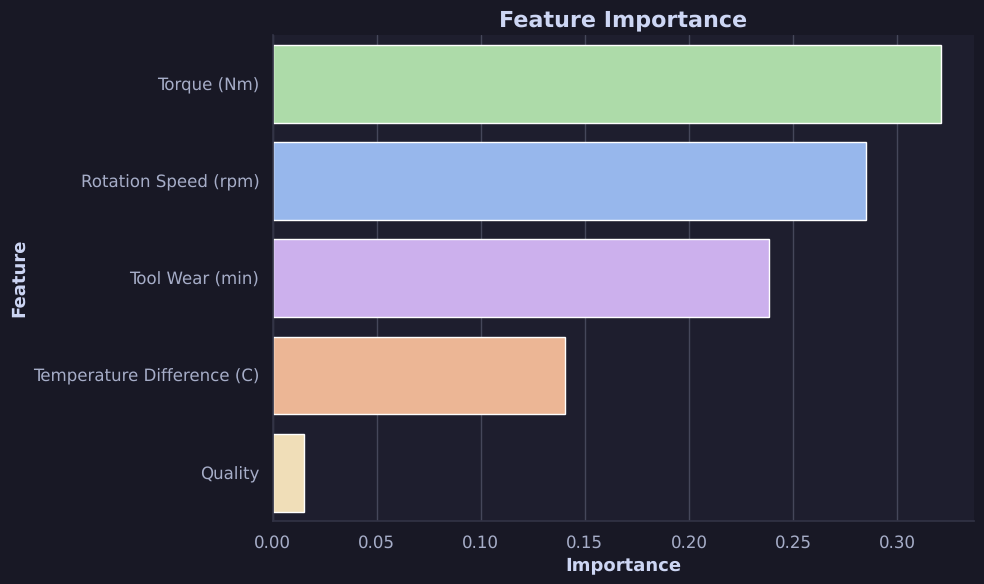

Torque (Nm)                   0.321
Rotation Speed (rpm)          0.285
Tool Wear (min)               0.239
Temperature Difference (C)    0.140
Quality                       0.015
dtype: float64

In [31]:
feature_palette = [
    flavour.colors.green.hex,
    flavour.colors.blue.hex,
    flavour.colors.mauve.hex,
    flavour.colors.peach.hex,
    flavour.colors.yellow.hex
]
# Fit the tuned pipeline on the training set and read the Random Forest's impurity-based importances.
importance_pipe = build_pipeline(RandomForestClassifier(random_state=42, **best_rf_params), features)
importance_pipe.fit(X_train, y_train)
importances = importance_pipe.named_steps["model"].feature_importances_
names = np.array(feature_names(features))
indices = np.argsort(importances)[::-1]
# Visualize feature importances by plotting a barplot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances[indices],
    y=names[indices],
    palette=feature_palette,
)
plt.title("Feature Importance", fontsize=16, fontweight='bold', color=flavour.colors.text.hex)
plt.xlabel("Importance", fontsize=13, fontweight='bold', color=flavour.colors.text.hex)
plt.ylabel("Feature", fontsize=13, fontweight='bold', color=flavour.colors.text.hex)
plt.xticks(fontsize=12, color=flavour.colors.subtext0.hex)
plt.yticks(fontsize=12, color=flavour.colors.subtext0.hex)
sns.despine()
plt.tight_layout()
plt.show()
pd.Series(importances, index=names).sort_values(ascending=False).round(3)


The impurity-based importance chart ranks **Torque (Nm)** (0.32) and **Rotation Speed (rpm)** (0.29) highest, followed by **Tool Wear (min)** (0.24) and **Temperature Difference (C)** (0.14), with **Quality** (0.02) last.

This ranking differs from the drop-column test, where Temperature Difference was the most important. The two methods measure different things: impurity importance counts how much each feature is used for splits, and it shares the credit between correlated features like Torque and Rotation Speed. The drop-column test measures how much performance is lost when a feature is missing, and it shows that no other feature can replace the information in Temperature Difference. Both methods agree that Quality matters least, but since removing it still lowers F1, we keep all five features in the final model.

We now train the final model on the full training set and evaluate it on the test set, for the first and only time.


Final features: ['Quality', 'Temperature Difference (C)', 'Torque (Nm)', 'Tool Wear (min)', 'Rotation Speed (rpm)']


              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3864
           1       0.86      0.95      0.90       136

    accuracy                           0.99      4000
   macro avg       0.93      0.97      0.95      4000
weighted avg       0.99      0.99      0.99      4000



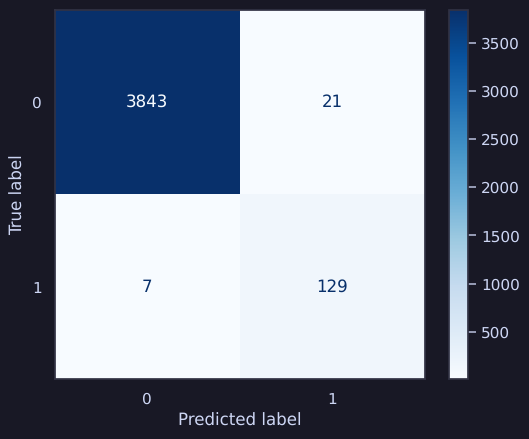

In [32]:
# Final model: keep every feature whose removal lowered the cross-validated F1.
final_features = [f for f in features if ablation_df.loc[f, "Change in F1"] < 0]
print(f"Final features: {final_features}")

final_model = build_pipeline(RandomForestClassifier(random_state=42, **best_rf_params), final_features)
final_model.fit(X_train[final_features], y_train)

# This is the first and only time the test set is used.
y_pred = final_model.predict(X_test[final_features])
print(classification_report(y_test, y_pred, zero_division=False))
cm = confusion_matrix(y_test, y_pred, labels=final_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=final_model.classes_)
fig, ax = plt.subplots()
disp.plot(ax=ax,cmap="Blues")
ax.grid(False)
plt.show()


#### ROC Curve Analysis

To further evaluate our final Random Forest model's performance, we will use a **Receiver Operating Characteristic (ROC) curve** to visualize the relationship between the True Positive Rate (TPR) and False Positive Rate (FPR) across different classification thresholds.

The ROC curve is useful as it provides information into the model's ability to distinguish between faulty and working machines at various thresholds. The curve plots:

-   **True Positive Rate (TPR)** on the y-axis: Also known as sensitivity or recall, it measures the proportion of actual faulty machines correctly identified
-   **False Positive Rate (FPR)** on the x-axis: The proportion of working machines incorrectly classified as faulty

The **Area Under the Curve (AUC)** metric summarizes the ROC curve performance, where:

-   AUC = 1.0 represents perfect classification
-   AUC = 0.5 represents random guessing (diagonal line)
-   Higher AUC values indicate better model discrimination ability

For our factory machine monitoring application, the ROC curve will help us understand the trade-off between catching faulty machines (high TPR) and minimizing false alarms (low FPR), which is crucial for operational decision-making.


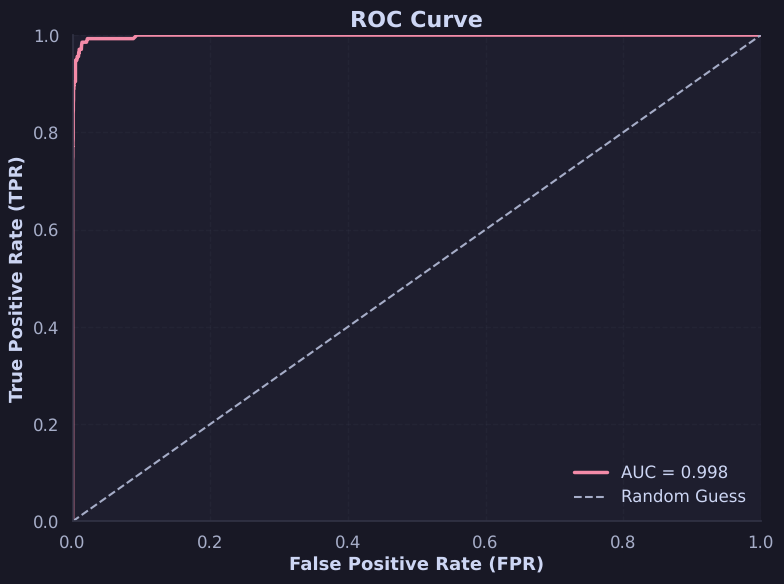

In [33]:
# Beautified ROC-AUC Curve visualization
y_proba = final_model.predict_proba(X_test[final_features])[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Define and plot a ROC-AUC curve.
plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr,
    color=flavour.colors.red.hex,
    linewidth=2.5,
    label=f"AUC = {roc_auc:.3f}"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color=flavour.colors.subtext0.hex,
    linewidth=1.5,
    label="Random Guess"
)
plt.xlabel("False Positive Rate (FPR)", fontsize=13, fontweight="bold", color=flavour.colors.text.hex)
plt.ylabel("True Positive Rate (TPR)", fontsize=13, fontweight="bold", color=flavour.colors.text.hex)
plt.title("ROC Curve", fontsize=16, fontweight="bold", color=flavour.colors.text.hex)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.legend(loc="lower right", frameon=False, fontsize=12)
plt.grid(alpha=0.15, linestyle="--")
plt.xticks(fontsize=12, color=flavour.colors.subtext0.hex)
plt.yticks(fontsize=12, color=flavour.colors.subtext0.hex)
for spine in ["top", "right"]:
    plt.gca().spines[spine].set_visible(False)
sns.despine()
plt.tight_layout()
plt.show()

### Using the Actual Model for Prediction

After training and tuning the Random Forest model, we can now use it to make predictions on new data. Because the final model is a pipeline, a raw row only needs the Temperature Difference feature added: imputation and scaling are applied with the statistics learned from the training set.

In [34]:
X_train[final_features].head()

,Quality,Temperature Difference (C),Torque (Nm),Tool Wear (min),Rotation Speed (rpm)
12791,2.0,9.2,43.3,66,1416.0
6582,0.0,9.0,35.7,198,1528.0
16873,0.0,10.4,39.5,75,1478.0
11391,0.0,11.3,8.8,142,2737.0
4410,0.0,7.7,32.2,64,1586.0


In [35]:
# Manually create a sample row
sample_row = {
    "Unique ID": 12345,
    "Product ID": "M14860",
    "Quality": 1,
    "Ambient T (C)": 32.0,
    "Process T (C)": 36.0,
    "Torque (Nm)": 53.0,
    "Rotation Speed (rpm)": 2500.0,
    "Tool Wear (min)": 100,
}
sample_df = pd.DataFrame([sample_row])
sample_df["Temperature Difference (C)"] = sample_df["Process T (C)"] - sample_df["Ambient T (C)"]
prediction = final_model.predict(sample_df[final_features])
print("Manual sample -> Predicted Machine Status:", "Faulty" if prediction[0] == 1 else "Working")

# Alternatively, take a faulty machine from the held-out test set.
sample_df = ori_df.loc[[y_test[y_test == 1].index[0]]].copy()
original_status = sample_df["Machine Status"].values[0]
print(f"\nTest-set sample -> Original Status: {'Faulty' if original_status == 1 else 'Working'}")

# Feature engineer: Temperature Difference
sample_df["Temperature Difference (C)"] = sample_df["Process T (C)"] - sample_df["Ambient T (C)"]

# Predict (the pipeline imputes and scales using training-set statistics)
prediction = final_model.predict(sample_df[final_features])
print("Test-set sample -> Predicted Machine Status:", "Faulty" if prediction[0] == 1 else "Working")


Manual sample -> Predicted Machine Status: Working

Test-set sample -> Original Status: Faulty
Test-set sample -> Predicted Machine Status: Faulty


## Reflection on Machine Learning Classification Model

### 1. Data Loading
Loaded the factory machine dataset containing 20,000 observations with 8 initial features: Unique ID, Product ID, Quality (L/M/H), Ambient Temperature, Process Temperature, Rotation Speed, Torque, and Tool Wear. The target variable Machine Status indicates working (0) or faulty (1) machines.

### 2. Data Cleaning / Exploratory Data Analysis
- **Missing values:** Quality (991), Process T (400) and Rotation Speed (1,188). They are imputed inside the modelling pipeline (mode for Quality, mean for the others), so the imputation values are learned from training data only.
- **Duplicates:** none.
- **Outliers:** 955 in Rotation Speed and 138 in Torque (IQR method), all kept as real measurements.
- **Encoding:** Quality converted to an ordinal number (L = 0, M = 1, H = 2).
- **Class imbalance:** 96.6% working vs 3.4% faulty machines.

### 3. Data Visualization
- Torque and Rotation Speed have a strong non-linear, inverse relationship (correlation −0.85), and faulty machines sit at its extremes.
- Ambient and Process Temperature are strongly correlated (0.87).

### 4. Data Preprocessing
- **Feature engineering:** Temperature Difference = Process T − Ambient T. Identifiers dropped.
- **Stratified 80/20 split** before any fitted preprocessing: 16,000 training and 4,000 test machines, both with 3.4% faults.
- **Leakage-free pipeline:** imputation → SMOTE-NC → StandardScaler → model, fitted only on training data (and re-fitted inside every cross-validation fold).

### 5. Model Training
Compared five algorithms with 5-fold stratified cross-validation on the training set (faulty-class F1): Random Forest 0.83, Gradient Boosting 0.49, KNN 0.49, SVM 0.42, Logistic Regression 0.23. All models reached high recall, but only Random Forest also kept precision high.

### 6. Hyperparameter Tuning
GridSearchCV over 72 combinations, scored on faulty-class F1 with the full pipeline in each fold. Best: `n_estimators=200, max_depth=None, max_features="sqrt", min_samples_leaf=1, min_samples_split=2`. Cross-validated F1 barely changed (0.829 → 0.830), so the default settings were already close to optimal.

### 7. Feature Importance
- **Drop-column test (cross-validated):** removing any feature lowers F1. Temperature Difference has the largest effect (−0.16), followed by Tool Wear (−0.14) and Torque (−0.14); Rotation Speed (−0.03) and Quality (−0.02) have the smallest.
- **Impurity importance:** Torque > Rotation Speed > Tool Wear > Temperature Difference > Quality.
- All five features are kept.

### 8. Final Model (test set, used once)
Tuned Random Forest on all five features:
- **Precision (faulty):** 0.86
- **Recall (faulty):** 0.95
- **F1-score (faulty):** 0.90
- **Accuracy:** 0.99
- **ROC-AUC:** 0.998

The test F1 (0.90) is higher than the cross-validated F1 (0.83). With only 136 faulty machines in the test set, a difference of this size is within normal sampling variation, and it shows no sign of overfitting. It catches 95% of faulty machines while keeping false alarms low, which makes it suitable for predictive maintenance.
